# Iris: agrupamiento y reducción de dimensionalidad

**Karen Sofía Delgado Calderon · Introducción a Machine Learning**

Este cuaderno sigue las guías de implementación de ML no supervisado y clustering del REA 1. Compara K-means, Ward y una exploración de DBSCAN; después relaciona PCA con la descomposición SVD. Las especies se reservan para una comprobación *posterior* y no intervienen en el ajuste.

## Cómo recorrer este cuaderno

Actividad **73638, R1-A3-S12: ML no supervisado**. Abre este archivo en Google Colab y elige **Entorno de ejecución > Ejecutar todo**. Los datos vienen con scikit-learn; no se necesita conectar Drive ni cargar archivos. Cada ejecución vuelve a escribir la carpeta `resultados/`.

[Informe APA en Overleaf](https://www.overleaf.com/project/6ae177ee4450dde92eea2078) · [Repositorio](https://github.com/sofiadelcal/karen-ml-no-supervisado-iris)

La pregunta es qué estructura aparece al agrupar Iris sin usar sus etiquetas y cuánto se pierde al proyectar las observaciones en dos ejes. Las etiquetas reales solo se consultan después del ajuste, al calcular ARI. Los colores de los gráficos representan clusters y sus números no tienen un orden natural.

Se conserva `random_state=42`, K-means con `n_init=20`, variables estandarizadas y evaluación en todas las dimensiones. PCA se utiliza después del agrupamiento para visualizar; no modifica las entradas de K-means ni de Ward.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import linkage, dendrogram
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, davies_bouldin_score, adjusted_rand_score

OUT = Path('resultados')
OUT.mkdir(exist_ok=True)
plt.rcParams.update({'figure.dpi': 130, 'font.size': 10, 'axes.spines.top': False,
                     'axes.spines.right': False})

from sklearn.datasets import load_iris
from sklearn.cluster import DBSCAN

In [2]:
datos = load_iris()
X_raw, y = datos.data, datos.target
X = StandardScaler().fit_transform(X_raw)
print(f'{X.shape[0]} flores, {X.shape[1]} medidas; faltantes: {np.isnan(X_raw).sum()}')
print('Variables:', ', '.join(datos.feature_names))

150 flores, 4 medidas; faltantes: 0
Variables: sepal length (cm), sepal width (cm), petal length (cm), petal width (cm)


## Supuestos que conviene revisar

K-means minimiza $J=\sum_j\sum_{x_i\in C_j}\|x_i-\mu_j\|_2^2$ alternando asignaciones y centroides. Favorece grupos compactos y puede cambiar al modificar la escala o la inicialización. Ward construye una jerarquía desde observaciones individuales y une los grupos que menos aumentan la dispersión interna. Un dendrograma truncado muestra ramas agregadas: cada hoja puede reunir varias muestras; su altura no es una probabilidad.

La silueta relaciona distancia media dentro del grupo ($a$) y al grupo vecino ($b$): $s=(b-a)/\max(a,b)$. Una cifra cercana a 1 indica mayor separación según esa distancia; cerca de 0 hay solapamiento. Davies–Bouldin resume dispersión relativa a la separación de grupos y se prefiere menor. ARI mide acuerdo entre particiones corrigiendo el azar; aquí usa las clases conocidas exclusivamente como diagnóstico externo. Estas medidas contestan preguntas distintas y no son porcentajes de exactitud.

Fuente: [documentación de clustering de scikit-learn](https://scikit-learn.org/stable/modules/clustering.html).

## 1. Elegir el número de grupos

Se comparan de 2 a 6 grupos sin usar la especie. La inercia siempre desciende al aumentar k; la silueta ayuda a juzgar separación, pero tampoco decide por sí sola qué agrupación es útil. Se mantiene k=3 para contrastar con el ejercicio de Iris de la guía del curso.

,k,inercia,silueta
0,2,222.3617,0.5818
1,3,139.8205,0.4599
2,4,114.0923,0.3845
3,5,90.8076,0.3455
4,6,80.0222,0.3220


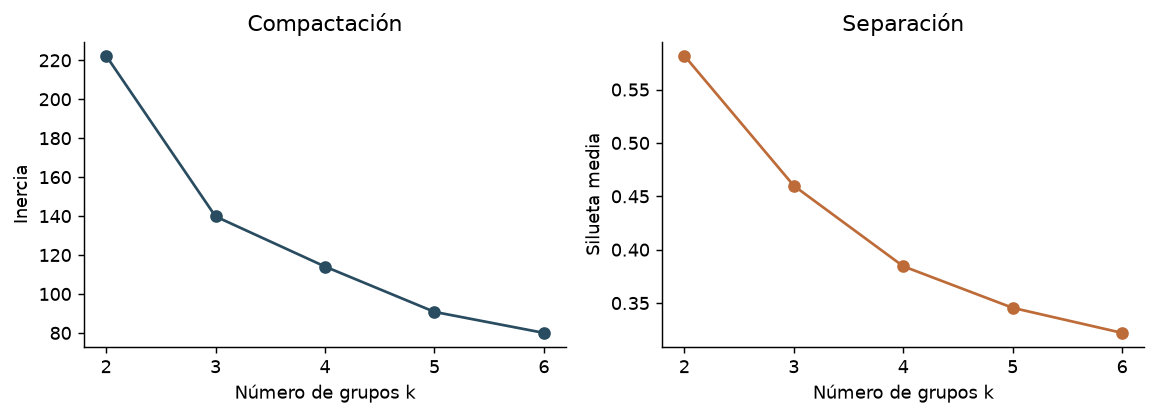

In [3]:
rows = []
for k in range(2, 7):
    fit = KMeans(n_clusters=k, n_init=20, random_state=42).fit(X)
    rows.append({'k': k, 'inercia': fit.inertia_,
                 'silueta': silhouette_score(X, fit.labels_)})
sweep = pd.DataFrame(rows)
display(sweep.round(4))
sweep.to_csv(OUT / 'seleccion_k.csv', index=False)

fig, axs = plt.subplots(1, 2, figsize=(9, 3.3))
axs[0].plot(sweep.k, sweep.inercia, 'o-', color='#294c60')
axs[0].set(xlabel='Número de grupos k', ylabel='Inercia', title='Compactación')
axs[1].plot(sweep.k, sweep.silueta, 'o-', color='#bd6b38')
axs[1].set(xlabel='Número de grupos k', ylabel='Silueta media', title='Separación')
for ax in axs: ax.set_xticks(sweep.k)
fig.tight_layout()
fig.savefig(OUT / 'seleccion_k.png', bbox_inches='tight')
plt.show()

## 2. Tres formas de agrupar

K-means minimiza distancias al centroide. Ward une grupos intentando limitar el aumento de varianza interna. DBSCAN se muestra como prueba de sensibilidad a densidad con parámetros explícitos; los puntos con etiqueta −1 se cuentan como ruido. El ARI usa las especies solo al final como diagnóstico externo.

In [4]:
km = KMeans(n_clusters=3, n_init=20, random_state=42).fit(X)
ward = AgglomerativeClustering(n_clusters=3, linkage='ward').fit(X)
db = DBSCAN(eps=0.7, min_samples=5).fit(X)

def evaluar(nombre, labels):
    grupos = len(set(labels) - {-1})
    ruido = int(np.sum(labels == -1))
    validos = labels != -1
    sil = silhouette_score(X[validos], labels[validos]) if 1 < grupos < int(validos.sum()) else np.nan
    dav = davies_bouldin_score(X[validos], labels[validos]) if 1 < grupos < int(validos.sum()) else np.nan
    return {'método': nombre, 'grupos': grupos, 'ruido': ruido,
            'silueta': sil, 'Davies-Bouldin': dav,
            'ARI externo': adjusted_rand_score(y, labels)}

comparacion = pd.DataFrame([evaluar('K-means', km.labels_),
                           evaluar('Ward', ward.labels_),
                           evaluar('DBSCAN', db.labels_)])
display(comparacion.round(4))
comparacion.to_csv(OUT / 'comparacion_metodos.csv', index=False)
print('Tamaños K-means:', np.bincount(km.labels_))
print('ARI entre K-means y Ward:', adjusted_rand_score(km.labels_, ward.labels_))

,método,grupos,ruido,silueta,Davies-Bouldin,ARI externo
0,K-means,3,0,0.4599,0.8336,0.6201
1,Ward,3,0,0.4467,0.8035,0.6153
2,DBSCAN,2,6,0.6018,0.5568,0.5401


Tamaños K-means: [53 50 47]
ARI entre K-means y Ward: 0.6255455129518299


## 3. PCA y SVD sobre la matriz estandarizada

PCA centra la matriz y obtiene ejes de máxima varianza. La SVD factoriza esa misma matriz centrada; al conservar dos valores singulares, su reconstrucción coincide con la de PCA salvo error numérico. El error de reconstrucción informa cuánta geometría se pierde al dibujar solo dos ejes.

In [5]:
pca = PCA(n_components=2).fit(X)
Z = pca.transform(X)
U, singular, Vt = np.linalg.svd(X - X.mean(axis=0), full_matrices=False)
X2 = (U[:, :2] * singular[:2]) @ Vt[:2, :] + X.mean(axis=0)
X2_pca = pca.inverse_transform(Z)
error_relativo = np.linalg.norm(X - X2) / np.linalg.norm(X - X.mean(axis=0))
coincidencia = np.max(np.abs(X2 - X2_pca))
varianza_2d = float(pca.explained_variance_ratio_.sum())
print(f'Varianza explicada por 2 CP: {varianza_2d:.4f}')
print(f'Error relativo de reconstrucción SVD rango 2: {error_relativo:.4f}')
print(f'Diferencia máxima entre reconstrucciones PCA y SVD: {coincidencia:.2e}')

Varianza explicada por 2 CP: 0.9581
Error relativo de reconstrucción SVD rango 2: 0.2046
Diferencia máxima entre reconstrucciones PCA y SVD: 1.67e-15


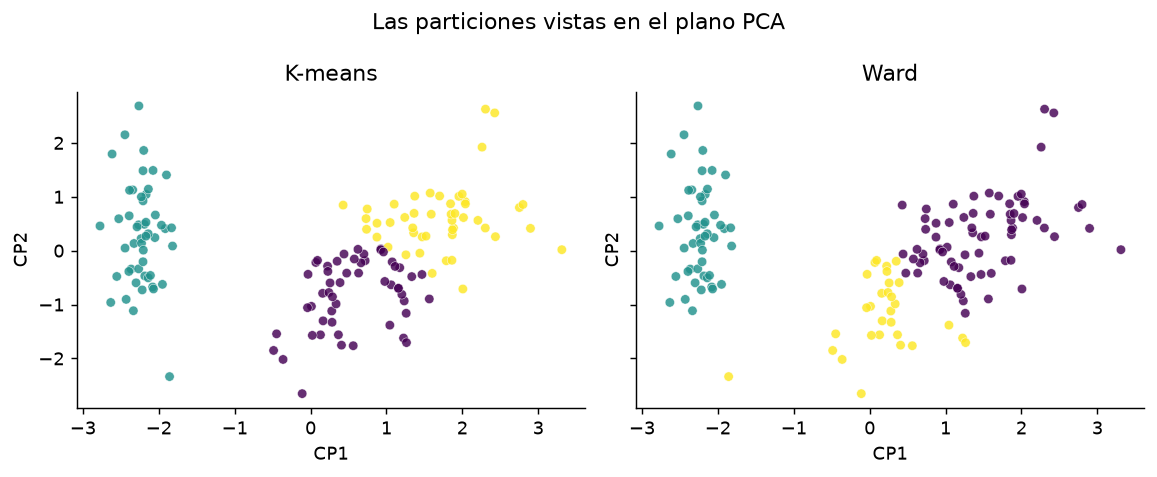

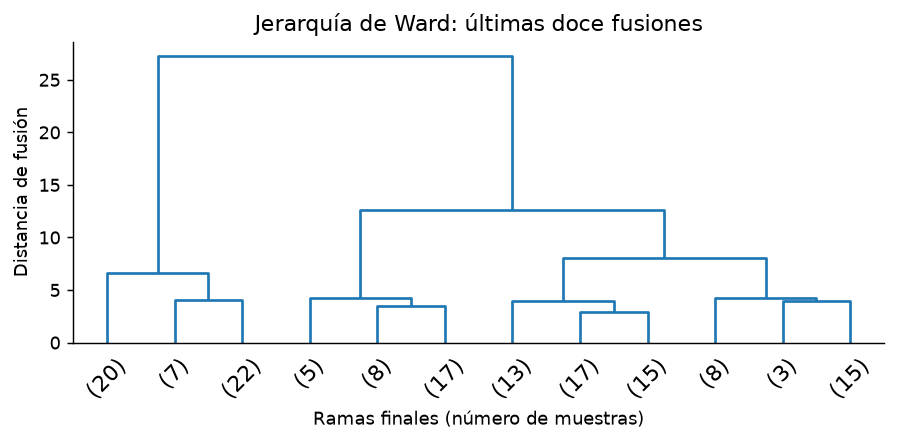

In [6]:
fig, axs = plt.subplots(1, 2, figsize=(9, 3.7), sharex=True, sharey=True)
for ax, labels, titulo in zip(axs, [km.labels_, ward.labels_], ['K-means', 'Ward']):
    ax.scatter(Z[:, 0], Z[:, 1], c=labels, cmap='viridis', s=27, alpha=.82,
               edgecolors='white', linewidths=.3)
    ax.set(xlabel='CP1', ylabel='CP2', title=titulo)
fig.suptitle('Las particiones vistas en el plano PCA')
fig.tight_layout()
fig.savefig(OUT / 'proyeccion_pca.png', bbox_inches='tight')
plt.show()

fig, ax = plt.subplots(figsize=(7, 3.5))
dendrogram(linkage(X, method='ward'), truncate_mode='lastp', p=12,
           show_leaf_counts=True, leaf_rotation=45, ax=ax, color_threshold=0)
ax.set(xlabel='Ramas finales (número de muestras)', ylabel='Distancia de fusión',
       title='Jerarquía de Ward: últimas doce fusiones')
fig.tight_layout()
fig.savefig(OUT / 'jerarquia_ward.png', bbox_inches='tight')
plt.show()

In [7]:
resumen = {'muestras': len(X), 'variables': X.shape[1],
           'silueta_k3': float(comparacion.loc[0, 'silueta']),
           'silueta_ward': float(comparacion.loc[1, 'silueta']),
           'ari_k3': float(comparacion.loc[0, 'ARI externo']),
           'ari_ward': float(comparacion.loc[1, 'ARI externo']),
           'dbscan_grupos': int(comparacion.loc[2, 'grupos']),
           'dbscan_ruido': int(comparacion.loc[2, 'ruido']),
           'varianza_pca2': varianza_2d, 'error_svd2': float(error_relativo),
           'diferencia_pca_svd': float(coincidencia),
           'mejor_k_silueta': int(sweep.loc[sweep.silueta.idxmax(), 'k']),
           'silueta_mejor': float(sweep.silueta.max())}
(OUT / 'resumen.json').write_text(json.dumps(resumen, indent=2), encoding='utf-8')
display(pd.Series(resumen, name='Resultado'))

muestras              1.500000e+02
variables             4.000000e+00
silueta_k3            4.599482e-01
silueta_ward          4.466890e-01
ari_k3                6.201352e-01
ari_ward              6.153230e-01
dbscan_grupos         2.000000e+00
dbscan_ruido          6.000000e+00
varianza_pca2         9.581321e-01
error_svd2            2.046165e-01
diferencia_pca_svd    1.665335e-15
mejor_k_silueta       2.000000e+00
silueta_mejor         5.817500e-01
Name: Resultado, dtype: float64

## Lectura crítica

Una proyección clara no prueba que los grupos estén separados en las cuatro variables. El número de especies es una referencia externa, no un parámetro aprendido. Para usar estos grupos en otro conjunto habría que comprobar estabilidad ante nuevas flores, otras escalas y distintas semillas.

## Qué dicen los resultados de Iris

La mejor silueta del barrido es **0,5818 con k=2**. Mantener k=3 permite contrastar la estructura del ejercicio del curso, pero no debe presentarse como el óptimo encontrado por esa métrica. K-means y Ward obtienen ARI externos de **0,6201 y 0,6153**: hay coincidencia parcial con las especies. K-means mejora la silueta frente a Ward, mientras Ward reduce Davies–Bouldin; el criterio elegido cambia la comparación.

DBSCAN produce **2 grupos y 6 observaciones de ruido**. Su silueta de **0,6018** excluye esas seis muestras y por eso no se compara como si evaluara las mismas 150 flores. La etiqueta -1 significa falta de densidad bajo los parámetros elegidos; no demuestra que una flor esté mal medida.

Las dos componentes retienen **95,81 %** de varianza. El error relativo SVD es **0,2046**: su cuadrado, aproximadamente **0,0419**, es la fracción de varianza descartada. El dendrograma se limita a doce hojas agregadas, no a doce observaciones individuales.

En un vivero, un análisis semejante podría orientar la revisión de lotes parecidos y mediciones atípicas. Habría que contrastarlo con conocimiento botánico y nuevas muestras antes de usarlo para tomar decisiones. No se ha medido estabilidad frente a otras semillas ni rendimiento sobre flores nuevas.

## Comprobaciones de consistencia

Estas comprobaciones detectan datos no finitos, cambios en la estandarización y desacuerdos algebraicos entre PCA y SVD. No prueban que los clusters sean verdaderos ni que el modelo generalice. Se permiten diferencias de redondeo de punto flotante entre bibliotecas.

In [8]:
import platform
from importlib.metadata import version

assert np.isfinite(X_raw).all(), 'Hay datos no finitos'
assert np.allclose(X.mean(axis=0), 0, atol=1e-10), 'Revisar el centrado'
assert np.allclose(X.std(axis=0), 1, atol=1e-10), 'Revisar la escala'
assert len(km.labels_) == len(X) and len(ward.labels_) == len(X)
assert np.allclose(X2, X2_pca, atol=1e-10), 'PCA y SVD no reconstruyen igual'
assert np.isclose(error_relativo**2, 1-varianza_2d, atol=1e-10)
assert (OUT / 'seleccion_k.csv').exists()
assert (OUT / 'comparacion_metodos.csv').exists()
assert (OUT / 'resumen.json').exists()
print('Comprobaciones superadas: datos, escala, particiones, reconstrucción y archivos.')
print(f'Error al cuadrado: {error_relativo**2:.6f}; varianza descartada: {1-varianza_2d:.6f}')
print('Python:', platform.python_version())
for paquete in ['numpy', 'pandas', 'scipy', 'scikit-learn', 'matplotlib']:
    print(f'{paquete}: {version(paquete)}')

Comprobaciones superadas: datos, escala, particiones, reconstrucción y archivos.
Error al cuadrado: 0.041868; varianza descartada: 0.041868
Python: 3.12.14
numpy: 2.5.4
pandas: 3.0.1
scipy: 1.18.1
scikit-learn: 1.9.1
matplotlib: 3.11.2


## Archivos y fuentes

- `resultados/seleccion_k.csv`: inercia y silueta para k entre 2 y 6.
- `resultados/comparacion_metodos.csv`: métricas de los tres algoritmos.
- `resultados/resumen.json`: cifras utilizadas en el informe.
- Las imágenes PNG se regeneran en las celdas de visualización.

Referencias: Scikit-learn developers (s. f.), [Clustering](https://scikit-learn.org/stable/modules/clustering.html), [PCA](https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.PCA.html) y [conjunto Iris](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_iris.html). Material del curso: Universidad de Cundinamarca (s. f.), guía de Clustering, REA 1. Las referencias completas y la discusión están en el [informe](https://www.overleaf.com/project/6ae177ee4450dde92eea2078).